In [51]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [52]:
from pathlib import Path
from magnetron.parameters import (
    GeometryParameters,
    MeshSettings,
    MagneticParameters,
    ElectrostaticParameters,
)
from magnetron.geometry import MagnetronGeometry
from magnetron.mesh import MagnetronMesh
from magnetron.magnetostatic import MagnetostaticSimulation
from magnetron.electrostatic import ElectrostaticSimulation
from magnetron.utils import FieldInterpolator2D, make_air_domain_checker
from magnetron.visualization import plot_electron_trajectories
from magnetron.trajectories import (
    ElectronTrajectory,
    ArgonGas,
    make_argon_collision_data,
    ELEMENTARY_CHARGE,
    ELECTRON_MASS,
)
from mpi4py import MPI
from dolfinx.io import gmsh as dolfinx_gmsh

In [53]:
results_dir = Path("../results/experiment")

geometry_parameters = GeometryParameters(
    target_diameter=0.0508,
    target_thickness=0.003,
    magnet_height=0.010,
    inner_magnet_diameter=0.018,
    outer_magnet_diameter=0.010,
    outer_magnet_ring_radius=0.022,
    magnet_to_target_distance=0.005,
    anode_cathode_gap=0.003,
    anode_width=0.004,
)

geometry = MagnetronGeometry(geometry_parameters)

mesh_path = MagnetronMesh(
    geometry,
    settings=MeshSettings(min_size=0.0001, max_size=0.001),
).generate(results_dir / "mesh.msh")

Info    : Meshing 1D...                                                                                                  
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 16 (Line)
Info    : [ 10%] Meshing curve 17 (Line)
Info    : [ 10%] Meshing curve 18 (Line)
Info    : [ 20%] Meshing curve 19 (Line)
Info    : [ 20%] Meshing curve 20 (Line)
Info    : [ 20%] Meshing curve 21 (Line)
Info    : [ 20%] Meshing curve 22 (Line)
Info    : [ 30%] Meshing curve 23 (Line)
Info    : [ 30%] Meshing curve 24 (Line)
Info    : [ 30%] Meshing curve 25 (Line)
Info    : [ 30%] Meshing curve 26 (Line)
Info    : [ 40%] Meshing curve 27 (Line)
Info    : [ 40%] Meshing curve 28 (Line)
Info    : [ 40%] Meshing curve 29 (Line)
Info    : [ 40%] Meshing curve 30 (Line)
Info    : [ 50%] Meshing curve 31 (Line)
Info    : [ 50%] Meshing curve 32 (Line)
Info    : [ 50%] Meshing curve 33 (Line)
Info    : [ 60%] Meshing curve 34 (Line)
Info    : [ 60%] Meshing curve 35 (Line)
Info    : [ 60%] 

In [54]:
magnetic_parameters = MagneticParameters(
    remanence=2.0,
    mu_r_air=1.0,
    mu_r_magnet=1.05,
    mu_r_backing=1.0,
)

magnetic_result = MagnetostaticSimulation(
    mesh_path,
    magnetic_parameters,
).solve(results_dir)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 5945 nodes
Info    : 11608 elements
Info    : Done reading '../results/experiment/mesh.msh'
Mesh coordinate bounds [m]:
  x: -0.04 0.04
  y: -0.03 0.03
Magnetostatic problem solved.
Fields: ../results/experiment/fields.xdmf
Metadata: ../results/experiment/simulation.json
|B| min/max [T]: 0.0008733943956864965 1.605512660827556


In [56]:
electrostatic_parameters = ElectrostaticParameters(
    target_voltage=-400.0, ground_voltage=0.0, eps_r_air=1.0
)

electrostatic_result = ElectrostaticSimulation(
    mesh_path, electrostatic_parameters
).solve(results_dir)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 5945 nodes
Info    : 11608 elements
Info    : Done reading '../results/experiment/mesh.msh'


In [57]:
field_interpolator = FieldInterpolator2D(
    electrostatic_result.domain,
    {
        "Ex": electrostatic_result.ex,
        "Ey": electrostatic_result.ey,
        "Bx": magnetic_result.bx,
        "By": magnetic_result.by,
    },
)


def electric_field(x, y):
    values = field_interpolator.evaluate_components(x, y)
    return values[0], values[1], 0.0


def magnetic_field(x, y):
    values = field_interpolator.evaluate_components(x, y)
    return values[2], values[3], 0.0

In [58]:
mesh_data = dolfinx_gmsh.read_from_msh(
    str(mesh_path),
    MPI.COMM_WORLD,
    gdim=2,
)

air_tag = mesh_data.physical_groups["Air"].tag

inside_air = make_air_domain_checker(
    mesh_data.mesh,
    mesh_data.cell_tags,
    air_tag,
)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 5945 nodes
Info    : 11608 elements
Info    : Done reading '../results/experiment/mesh.msh'


In [59]:
argon = ArgonGas(
    pressure_pa=0.2,
    temperature_k=300.0,
)

collision_data = make_argon_collision_data()

sim = ElectronTrajectory(
    electric_field=electric_field,
    magnetic_field=magnetic_field,
    inside_domain=inside_air,
    gas=argon,
    collision_data=collision_data,
    seed=42,
)

print(f"Argon number density: {argon.number_density():.3e} m⁻³")

Argon number density: 4.829e+19 m⁻³


In [60]:
import numpy as np

rng = np.random.default_rng(123)

N = 500
duration = 200e-9
max_step = 2e-11
max_electrons = 32

source_y = geometry_parameters.target_thickness + 0.1e-3

x_candidates = np.linspace(
    -geometry_parameters.target_diameter / 2 + 0.3e-3,
    geometry_parameters.target_diameter / 2 - 0.3e-3,
    N,
)

cascades = []
truncated_cascades = 0
trajectories = []
all_ionizations = []

for i, x_start in enumerate(x_candidates):
    x0 = float(x_start)
    y0 = float(source_y)

    if not inside_air(x0, y0):
        print(f"Skipped starting point x={x0 * 1e3:.2f} mm")
        continue

    energy_ev = rng.uniform(1.0, 3.0)
    speed = np.sqrt(2.0 * energy_ev * ELEMENTARY_CHARGE / ELECTRON_MASS)
    theta = rng.normal(0.0, np.deg2rad(10.0))
    phi = rng.uniform(0.0, 2.0 * np.pi)
    initial_velocity = (
        speed * np.sin(theta) * np.cos(phi),
        speed * np.cos(theta),
        speed * np.sin(theta) * np.sin(phi),
    )

    cascade = sim.solve_cascade(
        initial_position=(x0, y0),
        initial_velocity=initial_velocity,
        duration=duration,
        max_step=max_step,
        max_electrons=max_electrons,
        rtol=1e-4,
        atol=1e-8,
    )

    cascades.append(cascade)
    truncated_cascades += cascade.truncated
    trajectories.extend(cascade.trajectories)
    all_ionizations.extend(cascade.ionizations)

    print(
        f"Source {i + 1}/{N}: "
        f"{len(cascade.trajectories)} tracked electrons, "
        f"{len(cascade.ionizations)} ionizations"
    )

print("\nSummary")
print("Electron trajectories simulated:", len(trajectories))
print("Total ionization events:", len(all_ionizations))
print("Cascades stopped by electron limit:", truncated_cascades)

Source 1/500: 1 tracked electrons, 0 ionizations
Source 2/500: 1 tracked electrons, 0 ionizations
Source 3/500: 1 tracked electrons, 0 ionizations
Source 4/500: 1 tracked electrons, 0 ionizations
Source 5/500: 1 tracked electrons, 0 ionizations
Source 6/500: 1 tracked electrons, 0 ionizations
Source 7/500: 1 tracked electrons, 0 ionizations
Source 8/500: 1 tracked electrons, 0 ionizations
Source 9/500: 1 tracked electrons, 0 ionizations
Source 10/500: 1 tracked electrons, 0 ionizations
Source 11/500: 1 tracked electrons, 0 ionizations
Source 12/500: 1 tracked electrons, 0 ionizations
Source 13/500: 1 tracked electrons, 0 ionizations
Source 14/500: 1 tracked electrons, 0 ionizations
Source 15/500: 1 tracked electrons, 0 ionizations
Source 16/500: 1 tracked electrons, 0 ionizations
Source 17/500: 1 tracked electrons, 0 ionizations
Source 18/500: 1 tracked electrons, 0 ionizations
Source 19/500: 1 tracked electrons, 0 ionizations
Source 20/500: 1 tracked electrons, 0 ionizations
Source 21

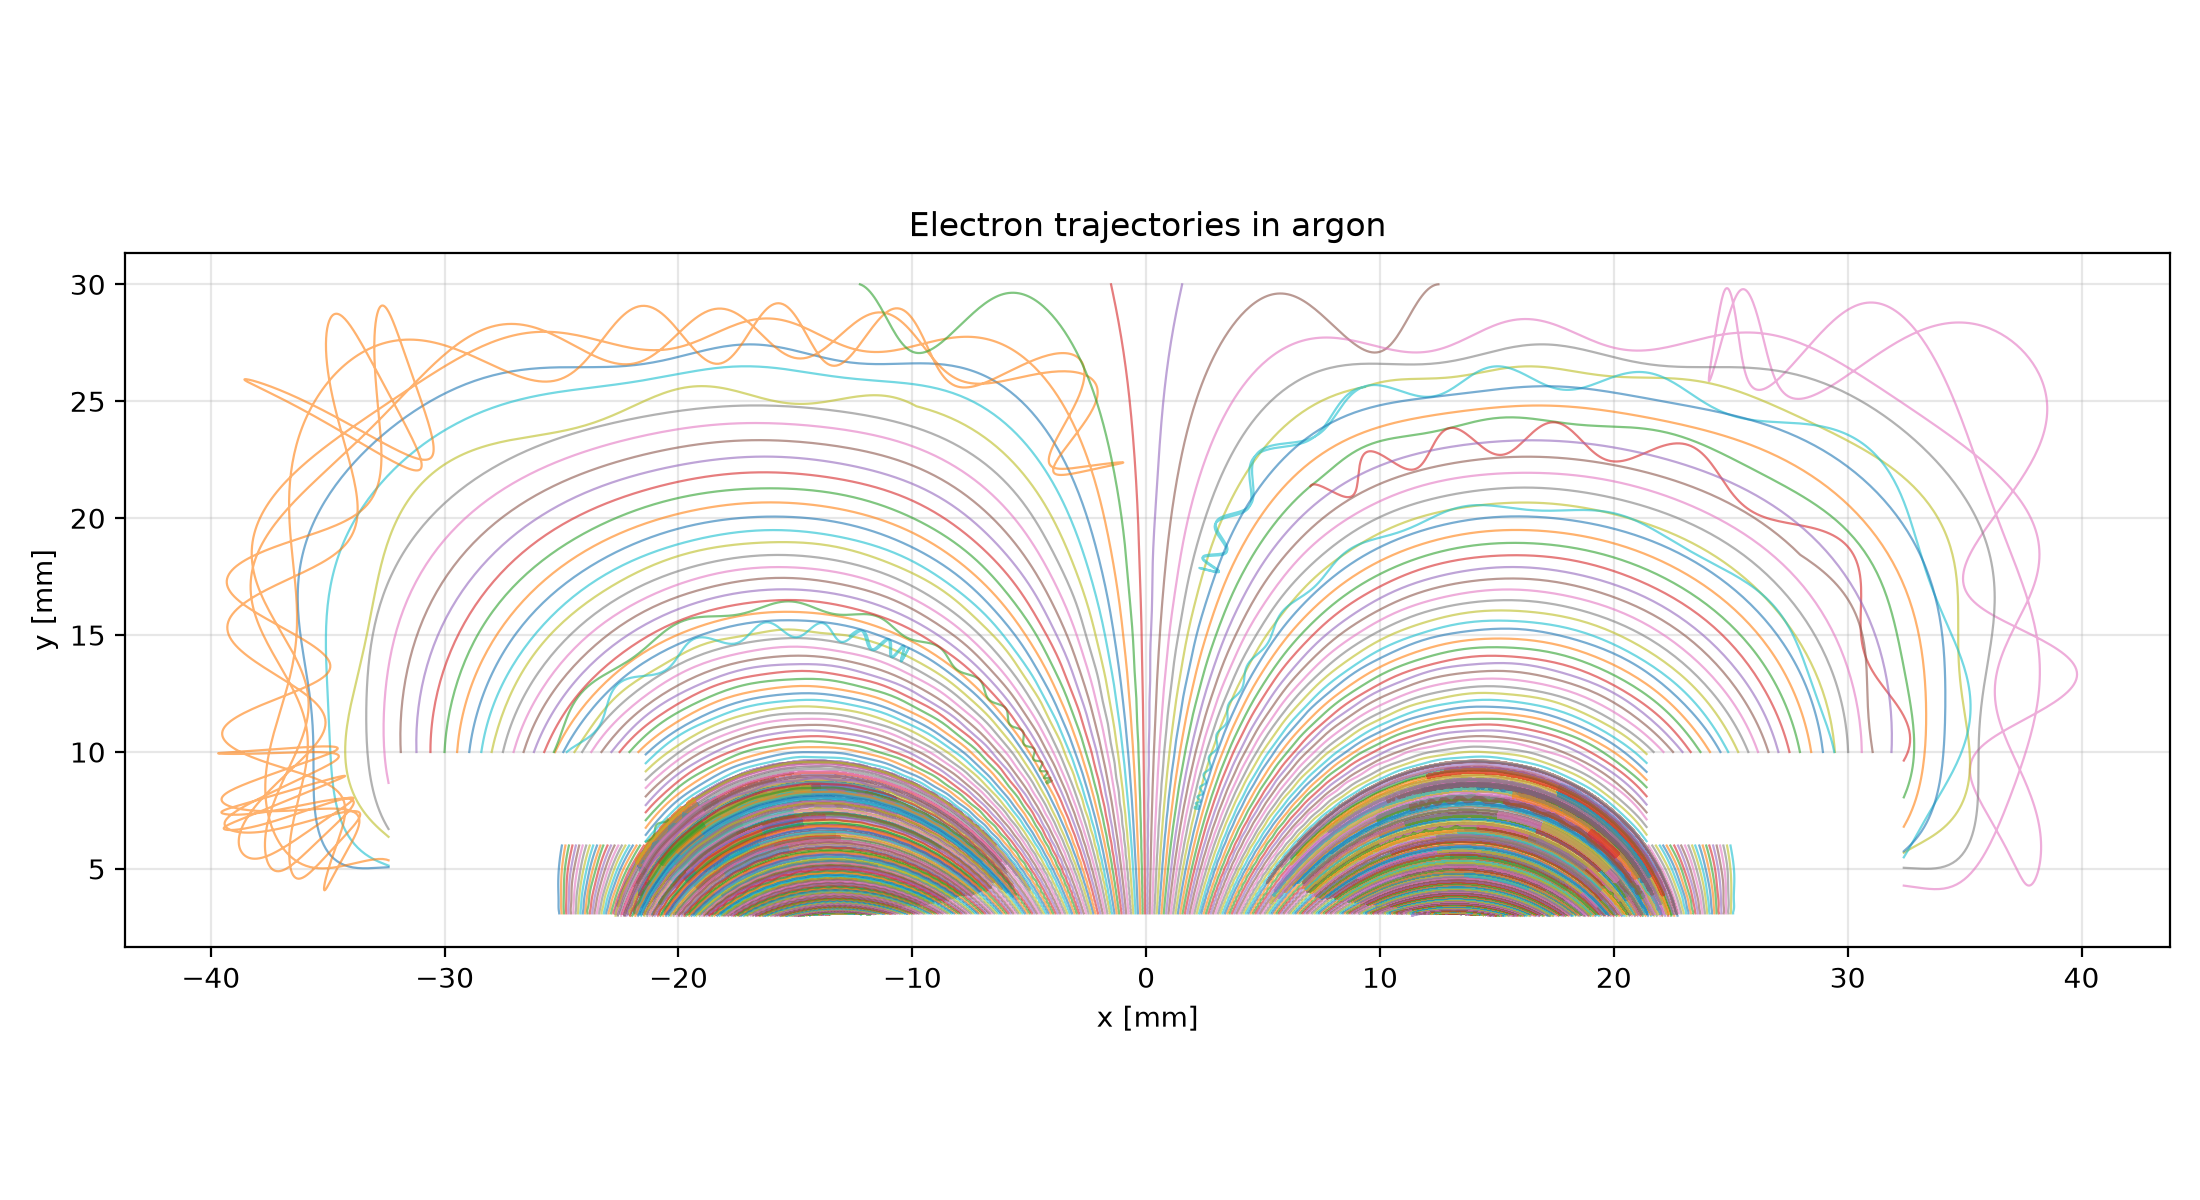

In [66]:
from IPython.display import Image, display

trajectories_plot_path = plot_electron_trajectories(
    trajectories, output_path=results_dir / "trajectory.png", ionizations=None
)

display(Image(filename=str(trajectories_plot_path)))